# 04 — Binary32 versus binary64, and rounding error in ULP units

**Goal.** Recreate Figures **07** and **08** of the English report: the predicted noisy regions at different floating-point precisions and the normalized sawtooth of rounding error.

**Sources.** *artigo_ulp.pdf*, Sections 2, 5, and 6; *livro_previa.pdf*, theoretical model and precision chapter.

In [1]:
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    raise FileNotFoundError('Open Jupyter in the extracted ULP_Jupyter_Reproducibility folder.')
sys.path.insert(0, str(ROOT / 'src'))
from ulp_lab import (evaluate, ulp, v2, floor_log2, theory, possible_results,
                     sample_binade, valid_same_binade_mask, generate_cases, validate_one)
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
BLUE='#2367A6'; ORANGE='#DD8A29'; GREEN='#2C977F'; RED='#B85751'; PURPLE='#8572AB'
plt.rcParams.update({'font.size':10,'figure.dpi':110,'savefig.dpi':190,
                     'axes.grid':True,'grid.alpha':.20,
                     'axes.spines.top':False,'axes.spines.right':False})
print('Working directory:', ROOT)
print('NumPy:', np.__version__)

Working directory: /mnt/data/ULP_Jupyter_Reproducibility
NumPy: 2.3.5


## The analytical model

Let $y=\mathrm{fl}(x^{10})$ and $u=\mathrm{ULP}(y)$. For the stored $c>0$:

$$E_1=p+\nu(c),\qquad E_2=p+\lfloor\log_2 c\rfloor,$$
$$x_1=2^{E_1/10},\quad x_2=2^{(E_2+1)/10},\quad L=E_2-E_1+1.$$

The simple nearest-grid rule is valid when $y\ge c$ and the addition does not cross the upper boundary of the current binade. In that domain the rounding error is at most half a ULP; half-integer ties require ties-to-even.

In [2]:
values=[(1,'1'),(3,'3'),(101,'101'),(.5,'1/2'),(.75,'3/4'),(.1,'0.1'),(1/3,'1/3')]
rows=[]
for dtype in [np.float64,np.float32]:
    for c,lab in values:
        t=theory(c,dtype)
        rows.append({'precision':dtype.__name__,'c':lab,'stored c':t.c,
                     'x1':t.x1,'x2':t.x2,'L':t.L})
df=pd.DataFrame(rows)
display(df.round(6)); df.to_csv(RES/'04_precision_comparison.csv',index=False)
assert theory(101,np.float32).x2 < theory(101,np.float64).x2

,precision,c,stored c,x1,x2,L
0,float64,1,1.000000,39.396621,42.224253,1
1,float64,3,3.000000,39.396621,45.254834,2
2,float64,101,101.000000,39.396621,64.000000,7
3,float64,1/2,0.500000,36.758347,39.396621,1
4,float64,3/4,0.750000,34.296751,39.396621,2
5,float64,0.1,0.100000,0.870551,32.000000,52
6,float64,1/3,0.333333,0.933033,36.758347,53
7,float32,1,1.000000,5.278032,5.656854,1
8,float32,3,3.000000,5.278032,6.062866,2
9,float32,101,101.000000,5.278032,8.574188,7


## Figure 07 — predicted noisy intervals in both precisions

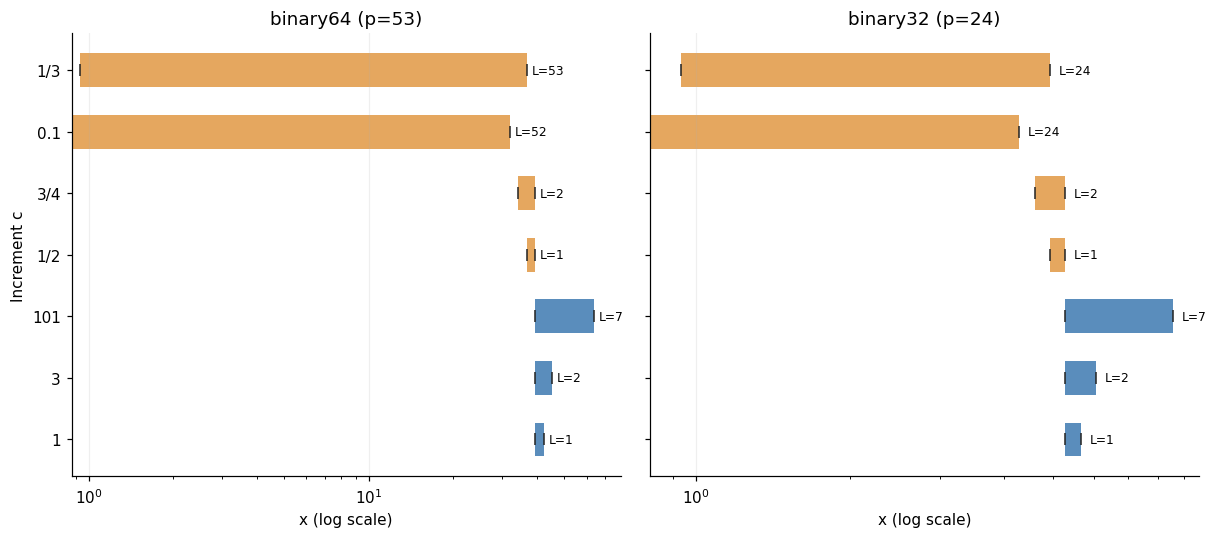

In [3]:
fig,axs=plt.subplots(1,2,figsize=(11.2,5.0),sharey=True)
for ax,dtype,title in zip(axs,[np.float64,np.float32],['binary64 (p=53)','binary32 (p=24)']):
    for i,(c,lab) in enumerate(values):
        t=theory(c,dtype)
        ax.barh(i,t.x2-t.x1,left=t.x1,height=.55,
                color=(BLUE if c==int(c) else ORANGE),alpha=.75)
        ax.plot([t.x1,t.x2],[i,i],'|',c='#222',ms=8)
        ax.text(t.x2*1.04,i,f'L={t.L}',va='center',fontsize=8)
    ax.set(xscale='log',xlabel='x (log scale)',title=title)
    ax.grid(axis='y',visible=False); ax.invert_yaxis()
axs[0].set_yticks(range(len(values)));axs[0].set_yticklabels([lab for c,lab in values]);axs[0].set_ylabel('Increment c')
fig.tight_layout()
fig.savefig(FIG / '07_precision_comparison.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## Figure 08 — measured normalized error and the sawtooth prediction

The calculation below **actually samples** points in selected binades, checks the validity conditions, and plots $\varepsilon=(f-c)/u$ against the fractional part of $q=c/u$. At ties ($q\bmod1=0.5$), both $+0.5$ and $-0.5$ may occur. This plot extends the purely conceptual sawtooth in the original figure by overlaying measured outcomes.

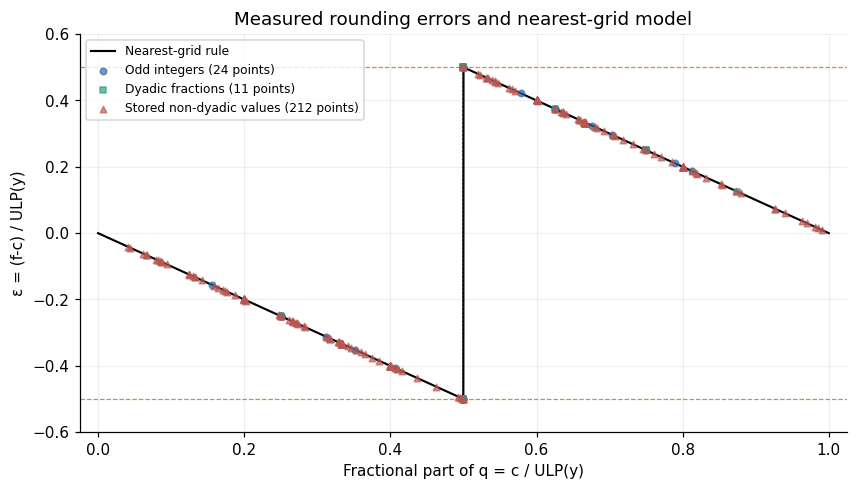

Measured model points: 247 maximum absolute ULP error: 0.5


In [4]:
rng=np.random.default_rng(2026)
categories={'Odd integers':[3,5,101,173],
            'Dyadic fractions':[.75,5/16,7/8],
            'Stored non-dyadic values':[.1,1/3,math.pi,math.e]}
observations=[]
for category,cs in categories.items():
    for c in cs:
        t=theory(c)
        for E in range(t.E1,t.E2+1):
            x,r,y,Er=sample_binade(c,E,count=350,rng=rng)
            valid,_,_=valid_same_binade_mask(y,c,E)
            usable=(Er==E)&valid
            u=math.ldexp(1.0,E-52)
            q=float(c)/u
            for observed in np.unique(r[usable]):
                eps=(float(observed)-c)/u
                observations.append({'family':category,'c':c,'E':E,
                                     'fractional q':q%1,'epsilon':eps})
obs=pd.DataFrame(observations)
assert len(obs)>120
assert np.abs(obs['epsilon']).max() <= .50000000001
obs.to_csv(RES/'04_measured_sawtooth_points.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4.7))
q=np.linspace(0,1,5000)
ax.plot(q,np.where(q<.5,-q,1-q),color='black',lw=1.4,label='Nearest-grid rule')
ax.plot([.5,.5],[-.5,.5],color='black',ls=':',lw=1)
for label,color,marker in [('Odd integers',BLUE,'o'),('Dyadic fractions',GREEN,'s'),
                           ('Stored non-dyadic values',RED,'^')]:
    part=obs[obs['family']==label]
    ax.scatter(part['fractional q'],part['epsilon'],color=color,s=18,
               marker=marker,alpha=.65,label=f'{label} ({len(part)} points)',zorder=3)
ax.axhline(.5,c=ORANGE,ls='--',lw=.8);ax.axhline(-.5,c=ORANGE,ls='--',lw=.8)
ax.set(xlim=(-.025,1.025),ylim=(-.6,.6),xlabel='Fractional part of q = c / ULP(y)',
       ylabel='ε = (f-c) / ULP(y)',title='Measured rounding errors and nearest-grid model')
ax.legend(fontsize=8,loc='upper left')
fig.savefig(FIG / '08_ulp_sawtooth.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)
print('Measured model points:',len(obs),'maximum absolute ULP error:',obs['epsilon'].abs().max())

## Conclusion

The *same* model works for binary32 and binary64 when its domain conditions hold, but lower precision shifts the critical values of `x` substantially to the left. Measured normalized errors lie within $[-0.5,+0.5]$ ULP on the tested validity domain, and half-ULP ties alternate according to parity.